In [ ]:
!pip install -q openai numpy matplotlib datasets pydantic

In [1]:
import json
import math
import os
import random
import re
import string
import time
import warnings
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass
from typing import Sequence

import matplotlib.pyplot as plt
import numpy as np
from datasets import load_dataset
from openai import OpenAI
from pydantic import BaseModel

warnings.filterwarnings("ignore")

os.environ["OPENAI_API_KEY"] = ""

client = OpenAI()
MODEL = "gpt-5-mini"
EMBED_MODEL = "text-embedding-3-small"
SEED = 0
NUM_TRAIN, NUM_VAL, NUM_TEST = 30, 30, 100
BUDGET = 270
NUM_WORKERS = 16
random.seed(SEED)
np.random.seed(SEED)

# 1) Prompt Optimization

A compound LLM system has two kinds of parameters: model weights and the natural-language instructions $\pi$ that program each
call. Weights need gradients, GPUs and thousands of rollouts. Instructions can be changed by
editing text, and with a hosted model they are the only parameters you control. 

**Prompt optimization** treats $\pi$ as the learnable object. It searches the space of instructions,
and optionally few-shot demonstrations, for the one that maximizes a task metric on held-out
data.

**Why it is hard.** The metric (exact match, test pass rate, a judge score) is not
differentiable, the search space is discrete and astronomically large, and every evaluation
costs real LLM calls. A method therefore lives or dies by how much *search direction* it
squeezes out of each rollout.

**What earlier approaches got wrong.** Hand-tuning does not scale and overfits to the cases
the engineer happened to look at. The first automatic methods (APE, OPRO) only see one scalar
score per candidate prompt. They learn *that* a prompt is worse, never *why*. The two methods
used most in practice today answer this in opposite ways:

| Method | Search signal | Search strategy | What it changes |
|---|---|---|---|
| **OPRO** (Yang et al., 2023) | scalar score history | LLM proposes from a sorted (prompt, score) list | instruction |
| **MIPROv2** (Opsahl-Ong et al., 2024) | scalar minibatch scores | bootstrapped demos + grounded proposals + Bayesian search (TPE) | instruction + few-shot demos |
| **GEPA** (Agrawal et al., 2025, ICLR 2026 oral) | per-example **textual feedback** from traces | reflective mutation + per-instance **Pareto** selection | instruction |

GEPA reports +10 points over MIPROv2 and up to +20 points over GRPO weight training with up to 35x fewer rollouts.

## 1.1 Data: Multi-Hop QA with a Retrieval Agent

HotpotQA questions need two Wikipedia paragraphs (*bridge* questions chain through an entity,
*comparison* questions contrast two entities). The distractor split ships each question with
its 2 gold paragraphs plus 8 lexically similar distractors. We pool the paragraphs of all 160
sampled questions into one index of about 1,600 paragraphs, so every search competes against
distractors from other questions as well.

The search tool embeds the query with `text-embedding-3-small` and returns the top-3
paragraphs by cosine similarity:

$$
\operatorname{sim}(q, d) = \frac{e_q^\top e_d}{\lVert e_q \rVert \, \lVert e_d \rVert},
\qquad
\operatorname{search}(q) = \operatorname*{top\text{-}3}_{d \in \mathcal{C}} \operatorname{sim}(q, d)
$$

where $e_q, e_d \in \mathbb{R}^{1536}$ are the query and paragraph embeddings and
$\mathcal{C}$ is the corpus.

| Split | Questions | Used for |
|---|---|---|
| train | 30 | feedback minibatches (GEPA), bootstrapped demos (MIPROv2) |
| val | 30 | candidate selection by every optimizer |
| test | 100 | final, untouched comparison |

In [2]:
# Sample 160 HotpotQA questions; each comes with 10 paragraphs (2 gold + 8 distractors)
hotpot = load_dataset("hotpotqa/hotpot_qa", "distractor", split="validation")
sample = hotpot.shuffle(seed=SEED).select(range(NUM_TRAIN + NUM_VAL + NUM_TEST))

# Pool every question's paragraphs into one shared corpus keyed by title
DOCS: dict[str, str] = {}
examples = []
for row in sample:
    for title, sentences in zip(row["context"]["title"], row["context"]["sentences"]):
        DOCS[title] = f"{title}: {''.join(sentences)}"
    examples.append(
        {
            "question": row["question"],
            "answer": row["answer"],
            "type": row["type"],
            # Paragraphs needed to answer; used only in feedback, never shown to the agent
            "gold_titles": sorted(set(row["supporting_facts"]["title"])),
        }
    )
# train = optimizer evidence, val = candidate selection, test = final report only
train_set = examples[:NUM_TRAIN]
val_set = examples[NUM_TRAIN : NUM_TRAIN + NUM_VAL]
test_set = examples[NUM_TRAIN + NUM_VAL :]
TITLES = list(DOCS)
print(
    f"{len(TITLES)} paragraphs, {len(train_set)}/{len(val_set)}/{len(test_set)} split"
)
print(json.dumps(train_set[0], indent=1))

1579 paragraphs, 30/30/100 split
{
 "question": "Glenn Quagmire is voiced by the creator of what 2012 film?",
 "answer": "Ted",
 "type": "bridge",
 "gold_titles": [
  "Glenn Quagmire",
  "Seth MacFarlane"
 ]
}


In [3]:
def embed(texts: Sequence[str]) -> np.ndarray:
    """Embed texts with the OpenAI embedding model.

    texts: (num_texts,) -> (num_texts, embed_dim), rows L2-normalized
    """
    response = client.embeddings.create(model=EMBED_MODEL, input=list(texts))
    vectors = np.array([item.embedding for item in response.data])
    return vectors / np.linalg.norm(vectors, axis=1, keepdims=True)


start = time.time()

# (num_docs, embed_dim)
DOC_EMBEDS = embed([DOCS[title] for title in TITLES])
print(f"index {DOC_EMBEDS.shape} built in {time.time() - start:.1f} s")

index (1579, 1536) built in 4.2 s


In [4]:
_query_cache: dict[str, np.ndarray] = {}


def search(query: str, k: int = 3) -> list[str]:
    """Return the titles of the k paragraphs most cosine-similar to the query."""
    # Cache query embeddings so repeated searches cost no API call
    if query not in _query_cache:
        _query_cache[query] = embed([query])[0]
    # (num_docs,) cosine similarities, since both sides are unit-norm
    sims = DOC_EMBEDS @ _query_cache[query]
    return [TITLES[i] for i in np.argsort(-sims)[:k]]


example = train_set[0]
print(example["question"], "| gold:", example["gold_titles"])
for title in search(example["question"]):
    print("  ->", DOCS[title][:110])

Glenn Quagmire is voiced by the creator of what 2012 film? | gold: ['Glenn Quagmire', 'Seth MacFarlane']
  -> Glenn Quagmire: Glenn Quagmire, often referred to as just Quagmire, is a character from the American animated 
  -> Seth MacFarlane: Seth Woodbury MacFarlane (born October 26, 1973) is an American actor, filmmaker, comedian, a
  -> Despicable Me 2: Despicable Me 2 is a 2013 American 3D computer-animated comedy film and the sequel to the 201


## 1.2 Metrics

HotpotQA's official answer metrics compare normalized strings (lower-cased, punctuation and
articles removed). For prediction tokens $P$ and gold tokens $G$ (as multisets):

$$
\mathrm{EM} = \mathbb{1}[P = G], \qquad
p = \frac{|P \cap G|}{|P|}, \quad r = \frac{|P \cap G|}{|G|}, \quad
\mathrm{F1} = \frac{2pr}{p + r}
$$

We optimize F1 because it is smoother than EM: a verbose but correct answer still earns
partial credit, which gives every optimizer a gradient-like ordering between candidates.

In [5]:
def normalize_answer(text: str) -> str:
    """HotpotQA/SQuAD normalization: lowercase, drop punctuation and articles."""
    text = text.lower()
    text = "".join(ch for ch in text if ch not in set(string.punctuation))
    text = re.sub(r"\b(a|an|the)\b", " ", text)
    return " ".join(text.split())


def exact_match(prediction: str, gold: str) -> float:
    """1.0 if the normalized strings are identical."""
    return float(normalize_answer(prediction) == normalize_answer(gold))


def f1_score(prediction: str, gold: str) -> float:
    """Token-level F1 between normalized prediction and gold."""
    pred_tokens = normalize_answer(prediction).split()
    gold_tokens = normalize_answer(gold).split()
    
    # Tokens shared by prediction and gold (with multiplicity)
    overlap = sum((Counter(pred_tokens) & Counter(gold_tokens)).values())
    if overlap == 0:
        return 0.0
    precision, recall = overlap / len(pred_tokens), overlap / len(gold_tokens)
    return 2 * precision * recall / (precision + recall)


for pred in ["Wharton School", "The Wharton School of the University of Pennsylvania."]:
    em, f1 = exact_match(pred, "Wharton School"), f1_score(pred, "Wharton School")
    print(f"{pred!r:60s} EM={em:.0f} F1={f1:.2f}")

'Wharton School'                                             EM=1 F1=1.00
'The Wharton School of the University of Pennsylvania.'      EM=0 F1=0.50


## 1.3 The Agent

The program $\Phi_\pi$ is a tool-calling loop. The instruction $\pi$ is the system prompt
(plus optional few-shot demos appended to it), the user turn is the bare question, and the
model may call `search` until it replies with plain text, which is the answer. Every rollout
records the searches it made and the paragraphs it saw. GEPA's feedback function needs both.

```
system: pi (+ demos)    user: question
        |
        v
  gpt-5-mini --tool_call--> search(query) --top-3 paragraphs--> back to gpt-5-mini
        |                                                         (up to 5 turns)
        v
  final text = answer  ->  EM, F1, retrieved titles
```

In [6]:
# The only tool the agent can call: semantic search over the paragraph corpus
TOOLS = [
    {
        "type": "function",
        "function": {
            "name": "search",
            "description": "Search a Wikipedia paragraph index. Returns the 3 most "
            "similar paragraphs.",
            "parameters": {
                "type": "object",
                "properties": {"query": {"type": "string"}},
                "required": ["query"],
            },
        },
    }
]


@dataclass
class Rollout:
    """One execution of the agent on one example."""

    answer: str
    searches: list[str]
    retrieved: set[str]
    em: float
    f1: float


def render_prompt(instruction: str, demos: Sequence[dict] = ()) -> str:
    """System prompt = instruction, followed by solved examples when demos are given."""
    if not demos:
        return instruction
    
    # Few-shot demos show question, searches made and answer
    blocks = [
        f"Question: {d['question']}\nSearches: {'; '.join(d['searches'])}\n"
        f"Answer: {d['answer']}"
        for d in demos
    ]
    return instruction + "\n\nExamples of solved questions:\n\n" + "\n\n".join(blocks)

In [7]:
def run_agent(system_prompt: str, example: dict, max_turns: int = 5) -> Rollout:
    """Run the search agent on one question and score its final answer."""
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": example["question"]},
    ]
    searches, retrieved, answer = [], set(), ""

    # Tool loop: search until the model replies without a tool call
    for _ in range(max_turns):
        response = client.chat.completions.create(
            model=MODEL, messages=messages, tools=TOOLS, reasoning_effort="minimal"
        )
        message = response.choices[0].message

        # A plain-text reply is the final answer
        if not message.tool_calls:
            answer = (message.content or "").strip()
            break
        messages.append(message.model_dump(exclude_none=True))

        for call in message.tool_calls:
            query = json.loads(call.function.arguments)["query"]
            titles = search(query)
            searches.append(query)
            retrieved.update(titles)
            content = "\n\n".join(DOCS[title] for title in titles)
            messages.append(
                {"role": "tool", "tool_call_id": call.id, "content": content}
            )
    
    # Score the final answer; F1 is the objective all optimizers maximize
    gold = example["answer"]
    return Rollout(
        answer, searches, retrieved, exact_match(answer, gold), f1_score(answer, gold)
    )


def evaluate(
    instruction: str, data: Sequence[dict], demos: Sequence[dict] = ()
) -> list[Rollout]:
    """Run the agent on every example in parallel; one rollout per example."""
    
    # The candidate being optimized = instruction (+ optional demos)
    system_prompt = render_prompt(instruction, demos)
    with ThreadPoolExecutor(NUM_WORKERS) as pool:
        return list(pool.map(lambda ex: run_agent(system_prompt, ex), data))


def mean_f1(rollouts: Sequence[Rollout]) -> float:
    """Average F1 over a list of rollouts."""
    return float(np.mean([r.f1 for r in rollouts]))

In [8]:
# Baseline prompt every optimizer starts from
SEED_PROMPT = (
    "Use the search tool to answer the question. "
    "Give only the final answer, as briefly as possible."
)

start = time.time()
# Seed val scores; reused as the starting point by all optimizers
seed_val = evaluate(SEED_PROMPT, val_set)
print(
    f"seed prompt on val: F1={mean_f1(seed_val):.3f} "
    f"EM={np.mean([r.em for r in seed_val]):.3f} ({time.time() - start:.0f} s)"
)
for ex, r in list(zip(val_set, seed_val))[:4]:
    print(
        f"  gold={ex['answer']!r:22s} pred={r.answer[:60]!r} searches={len(r.searches)}"
    )

seed prompt on val: F1=0.557 EM=0.300 (10 s)
  gold='John Waters'          pred='John Waters.' searches=1
  gold='yes'                  pred='Yes. Both the Tundra Mine and the Negus Mine were located in' searches=2
  gold='Mika Häkkinen'        pred='Mika Häkkinen.' searches=1
  gold='Barbra Streisand'     pred='Please specify the person you mean (the question is incomple' searches=1


## 1.4 Feedback Function

GEPA's central practical change is to the metric's interface. A metric $\mu$ returns a number.
A **feedback function** $\mu_f$ returns the number *plus text* that explains it. The text
draws on everything the evaluator can see: the gold answer, the agent's answer, and which gold
paragraphs the agent's searches did or did not retrieve.

$$
\mu_f(x, \Phi_\pi(x), y) \;\to\; (\text{score} \in [0, 1],\; \text{feedback text})
$$

The feedback states facts only. It does not prescribe a fix ("be shorter"). Inferring the fix
is the reflection model's job, and stating facts keeps the function task-agnostic.

In [9]:
def feedback(example: dict, rollout: Rollout) -> str:
    """Feedback text for one rollout: gold vs predicted, scores, retrieval coverage."""
    gold_titles = set(example["gold_titles"])
    
    # Retrieval diagnosis: which gold paragraphs were found vs missed
    found = sorted(gold_titles & rollout.retrieved) or "none"
    missed = sorted(gold_titles - rollout.retrieved) or "none"
    return (
        f"Gold answer: {example['answer']!r}. Predicted: {rollout.answer!r}. "
        f"EM={rollout.em:.0f}, F1={rollout.f1:.2f}. Searches: {rollout.searches}. "
        f"Gold paragraphs retrieved: {found}; missed: {missed}."
    )


print(feedback(val_set[0], seed_val[0]))

Gold answer: 'John Waters'. Predicted: 'John Waters.'. EM=1, F1=1.00. Searches: ["18th Independent Spirit Awards 2002 host who hosted 18th Independent Spirit Awards 2003 2002 'host' 'Independent Spirit Awards' 18th"]. Gold paragraphs retrieved: ['18th Independent Spirit Awards']; missed: ['John Waters'].


## 1.5 Optimization

Let $\Pi$ be the space of instructions (and demo sets), $\Phi_\pi$ the program run with
$\pi \in \Pi$, $\mu$ the metric and $D_{\text{val}} = \{(x_i, y_i)\}_{i=1}^{N}$ the validation
set. Prompt optimization solves

$$
\pi^\star = \operatorname*{arg\,max}_{\pi \in \Pi} \;
\frac{1}{N}\sum_{i=1}^{N} \mu\big(\Phi_\pi(x_i), y_i\big)
\quad \text{subject to at most } B \text{ rollouts,}
$$

with no gradient $\nabla_\pi \mu$: $\pi$ is discrete text and $\mu$ is a black box. Each method
below replaces the gradient with a different source of search direction:

| Method | Direction comes from | Cost per new candidate |
|---|---|---|
| OPRO | an LLM reading the history $\{(\pi_k, \bar\mu_k)\}$ | full val evaluation |
| MIPROv2 | a surrogate $p(\text{config} \mid \text{score})$ fitted to past trials | one minibatch per trial |
| GEPA | an LLM reading per-example traces and $\mu_f$ feedback | minibatch, then val only if it improves |

All three spend about $B = 270$ rollouts on train/val. The seed's val evaluation is shared
and not counted.

In [10]:
class Proposals(BaseModel):
    """Structured output: a list of candidate instructions."""
    instructions: list[str]


def ask_llm(prompt: str, effort: str = "low") -> str:
    """One plain-text call to the optimizer LLM."""
    response = client.chat.completions.create(
        model=MODEL,
        messages=[{"role": "user", "content": prompt}],
        reasoning_effort=effort,
    )
    return response.choices[0].message.content.strip()

# Structured output so OPRO gets a clean list of candidate instructions
def ask_proposals(prompt: str, effort: str = "low") -> list[str]:
    """One call that returns a parsed list of instructions."""
    response = client.chat.completions.parse(
        model=MODEL,
        messages=[{"role": "user", "content": prompt}],
        response_format=Proposals,
        reasoning_effort=effort,
    )
    return response.choices[0].message.parsed.instructions

---

# 2) OPRO: Optimization by PROmpting

OPRO (Yang et al., 2023) uses the LLM itself as the optimizer. The meta-prompt shows the
best instructions found so far, **sorted in ascending score order** (the paper found that
putting the best last works best), together with a few task exemplars, and asks for new
instructions that score higher. Each step:

$$
\{\pi^{(t)}_j\}_{j=1}^{m} \sim \mathrm{LLM}\Big(\text{meta-prompt}\big(\text{top-}k\text{ of }
\{(\pi_s, \bar\mu_s)\}_{s<t},\ \text{exemplars}\big)\Big),
\qquad \bar\mu_s = \text{mean val F1 of } \pi_s
$$

The only signal is $\bar\mu_s$. The optimizer sees that one instruction beat another, but not
which questions it fixed or broke.

In [11]:
# OPRO: the LLM sees past (instruction, score) pairs and proposes better ones
OPRO_META_PROMPT = """You are optimizing the system instruction of an assistant \
that answers multi-hop Wikipedia questions using a search tool. Answers are scored by \
token F1 against the gold answer (higher is better).

Previous instructions and their scores, from worst to best:
{history}

Example questions with their gold answers:
{exemplars}

Write {num} new instructions. Each must differ from all previous ones and aim for a \
higher score than the best one so far."""


def run_opro(steps: int = 3, per_step: int = 3, top_k: int = 8) -> dict:
    """OPRO loop: best instruction plus its (rollouts, best F1) trajectory."""
    history = [(SEED_PROMPT, mean_f1(seed_val))]
    used, trajectory = 0, [(0, history[0][1])]

    # A few Q/A pairs so the optimizer knows the task and answer style
    exemplars = "\n".join(
        f"Q: {ex['question']}\nA: {ex['answer']}" for ex in random.sample(train_set, 5)
    )

    for step in range(steps):
        # Show the top_k instructions in ascending score so the best is last
        shown = sorted(history, key=lambda h: h[1])[-top_k:]
        lines = "\n".join(f"Instruction: {p}\nScore: {s:.3f}\n" for p, s in shown)
        prompt = OPRO_META_PROMPT.format(
            history=lines, exemplars=exemplars, num=per_step
        )

        # Score every proposal on the full val set (costly: 30 rollouts each)
        for candidate in ask_proposals(prompt)[:per_step]:
            score = mean_f1(evaluate(candidate, val_set))
            used += len(val_set)
            history.append((candidate, score))
            trajectory.append((used, max(s for _, s in history)))
            print(f"step {step} val F1={score:.3f} | {candidate[:80]!r}")

    # Pick the highest val F1 instruction seen
    best_prompt, best_score = max(history, key=lambda h: h[1])
    return {
        "instruction": best_prompt,
        "demos": [],
        "val_f1": best_score,
        "rollouts": used,
        "trajectory": trajectory,
    }

In [12]:
start = time.time()
opro = run_opro()
print(
    f"\nOPRO best val F1={opro['val_f1']:.3f}, {opro['rollouts']} rollouts, "
    f"{time.time() - start:.0f} s\n{opro['instruction']}"
)

step 0 val F1=0.680 | 'Use the search tool iteratively to resolve multi-hop questions: run one or more '


step 0 val F1=0.711 | 'Always use the search tool to verify each entity/claim needed to answer multi-ho'


step 0 val F1=0.587 | 'When a question requires chaining facts, perform each search necessary to confir'


step 1 val F1=0.629 | 'For multi-hop Wikipedia questions, use the search tool iteratively to verify eve'


step 1 val F1=0.700 | 'When resolving chained or comparison questions, run focused searches for each en'


step 1 val F1=0.704 | 'Always verify names, dates, codes and list order by consulting the relevant Wiki'


step 2 val F1=0.689 | 'For every multi-hop Wikipedia question, iteratively use the search tool and foll'


step 2 val F1=0.384 | 'When resolving chained or comparative queries, perform focused searches for ever'


step 2 val F1=0.583 | 'Use the search tool repeatedly to validate names, dates, codes, and list orderin'

OPRO best val F1=0.711, 270 rollouts, 112 s
Always use the search tool to verify each entity/claim needed to answer multi-hop questions. After verification, return only the short, exact final answer (no explanation). For answers that include specific codes or multi-part items (e.g., "IATA: VNO, ICAO: EYVI" or lists of states), match the Wikipedia formatting and ordering.


---

# 3) MIPROv2

MIPROv2 (Opsahl-Ong et al., 2024, the default optimizer in DSPy) optimizes **instructions and
few-shot demonstrations jointly**, in three stages:

1. **Bootstrap demos.** Run the seed program on train examples and keep the traces that
   scored well. These are real input/search/output demonstrations that the model itself
   produced, so they show a working strategy, not just a gold label.
2. **Grounded instruction proposal.** A proposer LLM writes candidate instructions from a
   summary of the dataset, a description of the program, the bootstrapped demos and a random
   style *tip* ("be concise", "use a persona", ...). The tips inject diversity.
3. **Bayesian search.** Each trial picks one (instruction, demo set) configuration, scores it
   on a small val minibatch, and a Tree-structured Parzen Estimator (TPE) chooses the next
   configuration to try. The best few configurations are then scored on the full val set.

## 3.1 TPE for Categorical Choices

TPE models $p(x \mid y)$ instead of $p(y \mid x)$. Split the past trials at the score quantile
$y^\star$ (top $\gamma$ fraction is "good"):

$$
p(x \mid y) =
\begin{cases}
\ell(x) & y \ge y^\star \\
g(x) & y < y^\star
\end{cases}
\qquad
\mathrm{EI}_{y^\star}(x) \;\propto\; \Big(\gamma + (1-\gamma)\,\frac{g(x)}{\ell(x)}\Big)^{-1}
$$

So maximizing expected improvement means maximizing $\ell(x)/g(x)$. For a configuration
$x = (x_1, \dots, x_D)$ of independent categorical choices with $K_d$ options each, use
Laplace-smoothed frequencies

$$
\ell(x) = \prod_{d=1}^{D} \frac{n^{\text{good}}_{d}(x_d) + 1}{n^{\text{good}} + K_d},
\qquad
g(x) = \prod_{d=1}^{D} \frac{n^{\text{bad}}_{d}(x_d) + 1}{n^{\text{bad}} + K_d}
$$

where $n^{\text{good}}_d(x_d)$ counts good trials that chose option $x_d$ for dimension $d$.
Draw candidates from $\ell$ and keep the one with the largest $\ell/g$.

In [13]:
def tpe_suggest(
    trials: Sequence[tuple[tuple[int, ...], float]],
    space: tuple[int, ...],
    rng: random.Random,
    gamma: float = 0.25,
    num_candidates: int = 24,
) -> tuple[int, ...]:
    """Categorical TPE: sample from l(x), return the candidate maximizing l(x)/g(x).

    trials: (num_trials,) of (config, score); space: (num_dims,) option counts K_d
    """

    # Split past trials: top gamma fraction = good, the rest = bad
    ranked = sorted(trials, key=lambda t: -t[1])
    num_good = max(1, math.ceil(gamma * len(ranked)))
    good = [config for config, _ in ranked[:num_good]]
    bad = [config for config, _ in ranked[num_good:]]

    # l(x) from good trials, g(x) from bad trials, per dimension
    def density(group: list, dim: int) -> np.ndarray:
        """Laplace-smoothed option frequencies of one dimension: (K_d,)."""
        counts = np.bincount([c[dim] for c in group], minlength=space[dim])
        return (counts + 1) / (len(group) + space[dim])

    good_probs = [density(good, d) for d in range(len(space))]
    bad_probs = [density(bad, d) for d in range(len(space))]
    best, best_ratio = None, -1.0

    # Sample candidates from l(x); keep the one with highest l(x)/g(x)
    for _ in range(num_candidates):
        config = tuple(
            rng.choices(range(k), weights=good_probs[d])[0] for d, k in enumerate(space)
        )
        ratio = np.prod(
            [good_probs[d][x] / bad_probs[d][x] for d, x in enumerate(config)]
        )
        if ratio > best_ratio:
            best, best_ratio = config, ratio
    return best

In [14]:
# sanity check on a known 6 x 4 objective whose optimum is config (4, 2)
rng = random.Random(SEED)

def true_score(config: tuple[int, ...]) -> float:
    """Noisy toy objective peaked at (4, 2)."""
    return (
        1.0 - 0.1 * abs(config[0] - 4) - 0.15 * abs(config[1] - 2) + rng.gauss(0, 0.05)
    )


# Random startup trials, then TPE should converge toward (4, 2)
trials = [((rng.randrange(6), rng.randrange(4)), 0.0) for _ in range(6)]
trials = [(c, true_score(c)) for c, _ in trials]
for _ in range(14):
    config = tpe_suggest(trials, (6, 4), rng)
    trials.append((config, true_score(config)))
print("last 8 suggestions:", [c for c, _ in trials[-8:]])

last 8 suggestions: [(4, 2), (4, 2), (4, 2), (4, 2), (4, 2), (4, 2), (4, 2), (4, 2)]


## 3.2 Bootstrapping Demos and Proposing Instructions

A train rollout becomes a demo when its answer is an exact match. The demo keeps the agent's
own search queries, so a demo teaches a retrieval strategy as well as an answer format. Demo
set 0 is empty, so the search can also decide that zero-shot is best.

The proposer prompt follows MIPROv2's grounding: a dataset summary written by the LLM from
train examples, a program description, sampled demos, and one random tip from DSPy's list.

In [15]:
# Random style tips diversify the proposed instructions
MIPRO_TIPS = [
    "Don't be afraid to be creative when creating the new instruction!",
    "Keep the instruction clear and concise.",
    "Make sure your instruction is very informative and descriptive.",
    "Provide the LM with a role or persona in the instruction.",
    "The instruction should include a high stakes scenario in which the LM must solve "
    "the task!",
]
PROGRAM_DESCRIPTION = (
    "The program is a tool-calling agent. Its "
    "system prompt is the instruction; the user "
    "turn is a question. It may call search(query), which returns the 3 most similar "
    "Wikipedia paragraphs, and its final plain-text reply is scored as the answer."
)


def bootstrap_demos(num_sets: int = 4, per_set: int = 3) -> tuple[list[list], int]:
    """Run the seed on train, keep exact-match traces as demos (set 0 = none)."""
    rollouts = evaluate(SEED_PROMPT, train_set)
    
    # Keep only exact-match traces that searched, as candidate few-shot demos
    good = [
        {"question": ex["question"], "searches": r.searches, "answer": r.answer}
        for ex, r in zip(train_set, rollouts)
        if r.em == 1.0 and r.searches
    ]
    rng = random.Random(SEED)

    # Demo set 0 is empty, so 'no demos' is also a searchable option
    sets = [[]] + [
        rng.sample(good, min(per_set, len(good))) for _ in range(num_sets - 1)
    ]
    return sets, len(train_set)


def propose_instructions(demo_sets: list[list], num: int = 5) -> list[str]:
    """MIPROv2-style grounded proposals, one per random tip, run in parallel."""
    shown = "\n".join(
        f"Q: {ex['question']}\nA: {ex['answer']}" for ex in train_set[:12]
    )

    # Grounding step 1: summarize what the dataset looks like
    summary = ask_llm(
        "Summarize the patterns in this dataset in 3 bullet points (question types, "
        f"answer format, what makes them hard):\n{shown}"
    )
    rng = random.Random(SEED)
    
    # Grounding step 2: pair each tip with a random demo set
    jobs = [(tip, rng.choice(demo_sets[1:])) for tip in rng.sample(MIPRO_TIPS, num)]

    def one(job: tuple[str, list]) -> str:
        """One proposal for a (tip, demo set) pair."""
        tip, demo_set = job
        demos = render_prompt("", demo_set)

        # Proposal sees summary + program + seed + demos + tip
        return ask_llm(
            f"Dataset summary:\n{summary}\n\nProgram:\n{PROGRAM_DESCRIPTION}\n\n"
            f"Current instruction:\n{SEED_PROMPT}\n{demos}\n\nTip: {tip}\n\n"
            "Propose one improved instruction. Reply with the instruction text only."
        )

    with ThreadPoolExecutor(num) as pool:
        return list(pool.map(one, jobs))

In [16]:
start = time.time()
demo_sets, bootstrap_cost = bootstrap_demos()
# Candidate instructions = seed + 5 grounded proposals
mipro_instructions = [SEED_PROMPT] + propose_instructions(demo_sets)
print(
    f"{len(demo_sets)} demo sets of sizes {[len(s) for s in demo_sets]}, "
    f"{len(mipro_instructions)} instructions ({time.time() - start:.0f} s)"
)
for i, instruction in enumerate(mipro_instructions):
    print(f"  [{i}] {instruction[:110]!r}")
print("demo example:\n" + render_prompt("", demo_sets[1][:1]))

4 demo sets of sizes [0, 3, 3, 3], 6 instructions (27 s)
  [0] 'Use the search tool to answer the question. Give only the final answer, as briefly as possible.'
  [1] 'You are a precise trivia-answering assistant. Use the search(query) tool to find the answer by returning and r'
  [2] 'You are an expert, high-stakes quiz assistant working under live, high-pressure conditions: a single exact fac'
  [3] 'When answering, always use the search(query) tool first (perform additional searches as needed) to retrieve Wi'
  [4] 'Always call search(query) as needed to retrieve Wikipedia paragraphs, use them to determine the single canonic'
  [5] 'You are a tool-using quiz-answer agent. For each user question: (1) Use the search(query) tool to retrieve the'
demo example:


Examples of solved questions:

Question: The seventh largest inhabited island in Hawaii has what remote wild beach?
Searches: seventh largest inhabited island in Hawaii remote wild beach; which is the seventh largest inhabited i

## 3.3 The Search Loop

Each trial costs one minibatch of 10 val questions. The first trials are random (TPE needs
data to fit $\ell$ and $g$), and the rest follow `tpe_suggest`. A configuration's estimate is
the mean of all its minibatch scores. At the end the top 3 configurations get a full val
evaluation and the winner is returned.

In [17]:
def run_mipro(
    instructions: list[str],
    demo_sets: list[list],
    used: int,
    num_trials: int = 15,
    num_startup: int = 5,
    minibatch: int = 10,
    top_full: int = 3,
) -> dict:
    """MIPROv2 search over (instruction index, demo set index) with categorical TPE."""
    rng = random.Random(SEED)

    # Search space: which instruction x which demo set
    space = (len(instructions), len(demo_sets))
    trials, trajectory, best_val = [], [(0, mean_f1(seed_val))], mean_f1(seed_val)

    # Random configs first, then TPE suggests promising ones
    for t in range(num_trials):
        if t < num_startup:
            config = (rng.randrange(space[0]), rng.randrange(space[1]))
        else:
            config = tpe_suggest(trials, space, rng)

        # Cheap noisy score on a val minibatch instead of full val
        batch = rng.sample(val_set, minibatch)
        score = mean_f1(evaluate(instructions[config[0]], batch, demo_sets[config[1]]))
        used += minibatch
        trials.append((config, score))
        trajectory.append((used, best_val))
        print(f"trial {t:2d} config={config} minibatch F1={score:.3f}")

    # Average minibatch scores per config (a config may be tried more than once)
    by_config: dict[tuple, list] = {}
    for config, score in trials:
        by_config.setdefault(config, []).append(score)
    ranked = sorted(by_config, key=lambda c: -np.mean(by_config[c]))[:top_full]
    results = []
    # Re-score only the top configs on the full val set
    for config in ranked:
        val_score = mean_f1(
            evaluate(instructions[config[0]], val_set, demo_sets[config[1]])
        )
        used += len(val_set)
        best_val = max(best_val, val_score)
        trajectory.append((used, best_val))
        results.append((val_score, config))
        print(f"full val config={config} F1={val_score:.3f}")
# Winner = best full-val F1
    val_score, (i, j) = max(results)
    return {
        "instruction": instructions[i],
        "demos": demo_sets[j],
        "val_f1": val_score,
        "rollouts": used,
        "trajectory": trajectory,
    }

In [18]:
start = time.time()
mipro = run_mipro(mipro_instructions, demo_sets, used=bootstrap_cost)
print(
    f"\nMIPROv2 best val F1={mipro['val_f1']:.3f} with {len(mipro['demos'])} demos, "
    f"{mipro['rollouts']} rollouts, {time.time() - start:.0f} s\n{mipro['instruction']}"
)

trial  0 config=(3, 3) minibatch F1=0.442


trial  1 config=(4, 1) minibatch F1=0.611


trial  2 config=(2, 0) minibatch F1=0.883


trial  3 config=(2, 1) minibatch F1=0.533


trial  4 config=(5, 0) minibatch F1=0.746


trial  5 config=(5, 0) minibatch F1=0.879


... (8 outputs left out)

trial 14 config=(1, 0) minibatch F1=0.633


full val config=(2, 0) F1=0.722


full val config=(1, 0) F1=0.672


full val config=(5, 0) F1=0.729

MIPROv2 best val F1=0.729 with 0 demos, 270 rollouts, 110 s
You are a tool-using quiz-answer agent. For each user question: (1) Use the search(query) tool to retrieve the top 3 Wikipedia paragraphs most relevant to the question. Craft queries that focus on the key entities and relationships in the question, try alternate phrasings or corrected spellings if the first query is ambiguous or returns no clear match. (2) Read the returned paragraphs to identify the single factual answer the task requires (a person’s full name, a precise title, an organization, a place, or a date). Verify canonical phrasing and disambiguate between similarly named entities by checking context in the paragraphs. (3) If the top-3 paragraphs are ambiguous or incomplete, run one additional targeted search. (4) Finally, output only the final answer in a single short line, using the exact canonical name or date format as found in Wikipedia (prefer full personal names when appropriat

---

# 4) GEPA: Reflective Prompt Evolution

GEPA (Agrawal et al., 2025) keeps a pool of candidate instructions and grows it by
**reflective mutation**. It runs a parent on a small train minibatch, collects the traces with
their $\mu_f$ feedback, and asks a reflection LLM to rewrite the instruction so it fixes what
the feedback shows. Two mechanisms make this sample-efficient:

- **Minibatch gating.** A child is first scored on the same minibatch as its parent and only
  earns a full val evaluation if it improves there. Most bad mutations cost 2 x 4 rollouts,
  not 30.
- **Pareto candidate selection.** The parent is not simply the best-mean candidate.

## 4.1 Pareto Candidate Selection

Let $S \in [0,1]^{K \times N}$ hold the val scores of the $K$ pool candidates on the $N$ val
instances. Instance $i$'s front is the set of candidates that achieve its best score:

$$
F_i = \{\, k : S_{k,i} = \max_{k'} S_{k',i} \,\}
$$

A candidate is kept if it is on at least one front, unless it is **dominated**: every front it
is on also contains another surviving candidate. Survivors are sampled with probability
proportional to the number of fronts they are on, $p(k) \propto |\{ i : k \in F_i \}|$.

Why not always mutate the best-mean candidate? The paper's ablation found that greedy
selection gets stuck. Every mutation refines one lineage, and the instructions that solve
*different* questions die out. Pareto selection keeps any candidate that is uniquely best on
some question in play, so lessons from that question can still propagate.

In [19]:
def select_candidate(scores: np.ndarray, rng: random.Random) -> int:
    """Sample a parent from the per-instance Pareto fronts.

    scores: (num_candidates, num_val) -> candidate index
    """
    # Best score achieved on each val question by any candidate
    best = scores.max(axis=0)

    # Per question: the set of candidates that hit that best score
    fronts = [
        set(np.flatnonzero(scores[:, i] == best[i])) for i in range(scores.shape[1])
    ]

    # Only candidates that are best on at least one question survive
    alive = set().union(*fronts)

    # visit weak candidates first so they are the ones pruned as dominated
    for k in sorted(alive, key=lambda c: scores[c].mean()):
        others = alive - {k}
        if all(front & others for front in fronts if k in front):
            alive = others

    # Weight = number of questions a candidate is best on
    counts = Counter(k for front in fronts for k in front if k in alive)
    candidates = sorted(counts)
    # Sample a parent proportional to that weight (keeps specialists alive)
    return rng.choices(candidates, weights=[counts[k] for k in candidates])[0]


# 4 candidates x 5 instances: 0 and 1 are specialists, 2 is never best, 3 duplicates 1
toy = np.array(
    [[1, 1, 0, 0, 0], [0, 0, 1, 1, 0], [0.5, 0.5, 0.5, 0.5, 0], [0, 0, 1, 1, 0]]
)
toy_rng = random.Random(SEED)
print(Counter(select_candidate(toy, toy_rng) for _ in range(1000)))

Counter({np.int64(0): 508, np.int64(3): 492})


## 4.2 Reflective Mutation

The reflection prompt below paraphrases the one published with GEPA. It asks the reflection
model to infer the task from the examples, copy niche domain facts and working strategies into
the instruction, and fix the failures the feedback reveals. It uses a higher reasoning effort
than the agent, since this one call decides the quality of the next candidate.

In [20]:
# GEPA reflection: read traces + feedback, write an improved instruction
REFLECTION_PROMPT = """I provided an assistant with the following instructions to \
perform a task for me:
```
{instruction}
```

The following are examples of task inputs given to the assistant, its responses, and \
feedback on how the response could be better:
```
{records}
```

Your task is to write a new instruction for the assistant. Read the inputs carefully \
and infer a detailed description of the task. Read all the responses and the feedback. \
Identify niche and domain-specific facts about the task (answer formats, conventions, \
what counts as correct) and include them in the instruction, since this information \
will not be available to the assistant later. If the assistant used a generalizable \
strategy that worked, include it as well. Provide the new instruction within ``` \
blocks."""


def reflective_mutation(
    instruction: str, batch: Sequence[dict], rollouts: Sequence[Rollout]
) -> str:
    """Propose a child instruction from the parent's minibatch traces + feedback."""
    
    # Show the reflector each question, answer and diagnostic feedback
    records = "\n\n".join(
        f"# Example {i + 1}\nQuestion: {ex['question']}\nResponse: {r.answer!r}\n"
        f"Feedback: {feedback(ex, r)}"
        for i, (ex, r) in enumerate(zip(batch, rollouts))
    )
    reply = ask_llm(
        REFLECTION_PROMPT.format(instruction=instruction, records=records),
        effort="medium",
    )
    
    # Take the instruction from the last ``` block of the reply
    blocks = re.findall(r"```(?:\w*\n)?(.*?)```", reply, flags=re.S)
    return (blocks[-1] if blocks else reply).strip()


start = time.time()
child = reflective_mutation(SEED_PROMPT, val_set[:4], seed_val[:4])
print(f"({time.time() - start:.0f} s)\n{child}")

(21 s)
You must use the search tool to find authoritative evidence (Wikipedia, major encyclopedias, official sites, reliable news) and then produce only the final answer — as briefly as possible and nothing else.

Formatting and content rules:
- Output exactly the answer text only. Do not add explanations, qualifiers, metadata, quotes, bullets, punctuation (no trailing period), or extra whitespace.
- For yes/no questions output exactly: yes or no (lowercase).
- For people, places, titles, etc., output the commonly used full name or title with correct capitalization and diacritics (as shown in reliable sources). No honorifics or extra words.
- If multiple distinct items are requested, output them as a comma-separated list (use a single space after each comma), nothing else.
- If you cannot find reliable evidence, output exactly: not found
- If the question is ambiguous, choose the most likely interpretation based on authoritative sources and answer it (do not ask for clarification). If 

## 4.3 The GEPA Loop

```
pool = [seed], S = [val scores of seed]
while rollouts < B:
    k      = select_candidate(S)                # Pareto sampling
    batch  = 4 random train examples
    parent = evaluate(pool[k], batch)           # fresh traces + feedback
    child  = reflective_mutation(pool[k], batch, parent)
    if sum F1(child on batch) > sum F1(parent on batch):
        pool += [child]; S += [evaluate(child, val)]
return argmax_k mean(S[k])
```

The GEPA paper also has a **system-aware merge** operator. For programs with several modules
(query writer, summarizer, answerer), it builds a child by taking, module by module, the
version that evolved in each of two lineages. Our program has a single instruction, so the
operator does not apply. It matters most for multi-module pipelines.

In [21]:
def run_gepa(budget: int = BUDGET, minibatch: int = 4) -> dict:
    """GEPA with reflective mutation, minibatch gating and Pareto selection."""
    rng = random.Random(SEED)
    pool = [SEED_PROMPT]

    # Per-question val F1 for every candidate in the pool; drives Pareto selection
    # (num_candidates, num_val)
    scores = np.array([[r.f1 for r in seed_val]])
    used, trajectory, step = 0, [(0, scores.mean(axis=1).max())], 0

    # Each iteration costs 2 minibatches (parent + child)
    while used + 2 * minibatch <= budget:

        # 1) Pick a parent from the Pareto front
        k = select_candidate(scores, rng)
        batch = rng.sample(train_set, minibatch)
        parent_rollouts = evaluate(pool[k], batch)

        # 2) Reflect on the parent's minibatch failures to write a child
        child = reflective_mutation(pool[k], batch, parent_rollouts)
        child_rollouts = evaluate(child, batch)
        used += 2 * minibatch

        # 3) Gate: child must beat parent on the same minibatch
        gain = sum(r.f1 for r in child_rollouts) - sum(r.f1 for r in parent_rollouts)
        status = "rejected"
        
        # 4) Only gated children pay for a full val run and join the pool
        if gain > 0 and used + len(val_set) <= budget:
            child_val = evaluate(child, val_set)
            used += len(val_set)
            pool.append(child)
            scores = np.vstack([scores, [r.f1 for r in child_val]])
            status = f"accepted, val F1={mean_f1(child_val):.3f}"
        trajectory.append((used, scores.mean(axis=1).max()))
        print(f"iter {step:2d} parent={k} minibatch gain={gain:+.2f} -> {status}")
        step += 1

    # Return the candidate with the best mean val F1
    best = int(scores.mean(axis=1).argmax())
    return {
        "instruction": pool[best],
        "demos": [],
        "val_f1": scores[best].mean(),
        "rollouts": used,
        "trajectory": trajectory,
        "scores": scores,
    }

In [22]:
start = time.time()
gepa = run_gepa()
print(
    f"\nGEPA best val F1={gepa['val_f1']:.3f}, pool of {len(gepa['scores'])}, "
    f"{gepa['rollouts']} rollouts, {time.time() - start:.0f} s\n{gepa['instruction']}"
)

iter  0 parent=0 minibatch gain=+1.70 -> accepted, val F1=0.748


iter  1 parent=0 minibatch gain=+0.85 -> accepted, val F1=0.767


iter  2 parent=2 minibatch gain=+0.00 -> rejected


iter  3 parent=2 minibatch gain=+0.00 -> rejected


iter  4 parent=0 minibatch gain=-0.14 -> rejected


iter  5 parent=2 minibatch gain=+1.00 -> accepted, val F1=0.742


iter  6 parent=2 minibatch gain=+0.00 -> rejected


iter  7 parent=2 minibatch gain=+0.50 -> accepted, val F1=0.724


iter  8 parent=0 minibatch gain=+2.42 -> accepted, val F1=0.719


iter  9 parent=2 minibatch gain=-0.07 -> rejected


iter 10 parent=1 minibatch gain=+0.67 -> accepted, val F1=0.756

GEPA best val F1=0.767, pool of 7, 268 rollouts, 385 s
You will use the search tool to answer a single short factual question and then output only the final answer — nothing else.

Rules and format:
- Use the search tool to confirm the answer (target authoritative sources such as Wikipedia, Britannica, official sites). Use focused queries that include the question keywords and any named candidates.
- Extract the minimal, direct answer that matches the question (a single name, single word, or short phrase). Do not include explanations, supporting details, qualifiers, or parenthetical notes.
- Output exactly that minimal answer only. Do not add quotes, trailing periods, extra punctuation, or surrounding text.
- For choice questions (e.g., "Which is public, A or B?"), output only the chosen option's name (e.g., "Rutgers University").
- For single-entity questions (e.g., "Who aided X?"), output only the entity name (e.g., "Ar

The score matrix shows what the Pareto front preserved. Each column is one val question, and
a cell is bright where that candidate earned full F1. Candidates that win different columns
stay selectable even when their mean is lower.

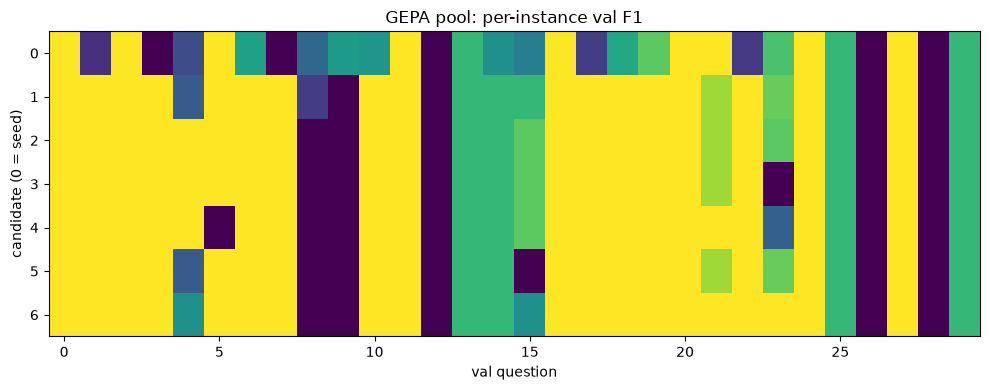

In [23]:
fig, ax = plt.subplots(figsize=(10, 0.4 * len(gepa["scores"]) + 1.2))
ax.imshow(gepa["scores"], aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_xlabel("val question")
ax.set_ylabel("candidate (0 = seed)")
ax.set_title("GEPA pool: per-instance val F1")
plt.tight_layout()
plt.show()

---

# 5) Held-Out Comparison

Every optimizer picked its winner on val, so val scores are optimistically biased. That is
the selection effect behind most non-replicating prompt-optimization gains. The 100 test
questions were seen by none of them.

In [24]:
methods = {
    "seed": {"instruction": SEED_PROMPT, "demos": [], "rollouts": 0},
    "OPRO": opro,
    "MIPROv2": mipro,
    "GEPA": gepa,
}
start = time.time()
test_results = {}
# Test set is touched exactly once per method, after optimization
for name, method in methods.items():
    rollouts = evaluate(method["instruction"], test_set, method["demos"])
    prompt = render_prompt(method["instruction"], method["demos"])
    test_results[name] = {
        "F1": mean_f1(rollouts),
        "EM": float(np.mean([r.em for r in rollouts])),
        "searches": float(np.mean([len(r.searches) for r in rollouts])),
        "prompt_chars": len(prompt),
        "opt_rollouts": method["rollouts"],
    }
print(f"test evaluation: {time.time() - start:.0f} s\n")
print(
    f"{'method':10s} {'test F1':>8s} {'test EM':>8s} {'searches':>9s} "
    f"{'prompt chars':>13s} {'opt rollouts':>13s}"
)
for name, r in test_results.items():
    print(
        f"{name:10s} {r['F1']:8.3f} {r['EM']:8.3f} {r['searches']:9.2f} "
        f"{r['prompt_chars']:13d} {r['opt_rollouts']:13d}"
    )

test evaluation: 110 s

method      test F1  test EM  searches  prompt chars  opt rollouts
seed          0.499    0.310      2.25            95             0
OPRO          0.731    0.580      2.76           329           270
MIPROv2       0.775    0.620      1.79           968           270
GEPA          0.767    0.640      1.91          1253           268


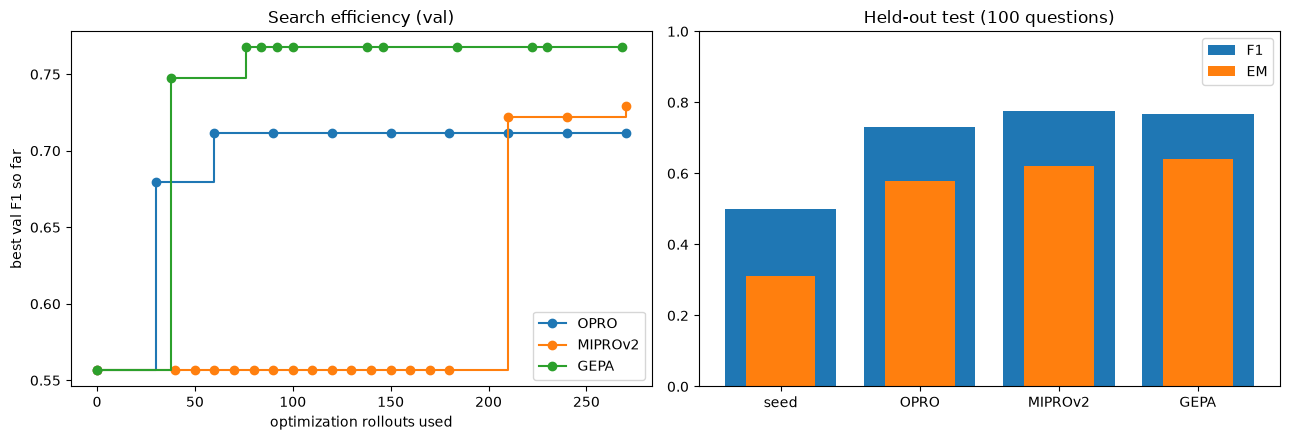

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name in ["OPRO", "MIPROv2", "GEPA"]:
    used, best = zip(*methods[name]["trajectory"])
    axes[0].step(used, best, where="post", marker="o", label=name)
axes[0].set_xlabel("optimization rollouts used")
axes[0].set_ylabel("best val F1 so far")
axes[0].set_title("Search efficiency (val)")
axes[0].legend()
names = list(test_results)
axes[1].bar(names, [test_results[n]["F1"] for n in names], color="tab:blue", label="F1")
axes[1].bar(
    names,
    [test_results[n]["EM"] for n in names],
    color="tab:orange",
    width=0.5,
    label="EM",
)
axes[1].set_title(f"Held-out test ({len(test_set)} questions)")
axes[1].set_ylim(0, 1)
axes[1].legend()
plt.tight_layout()
plt.show()

In this run all three optimizers end far above the seed (test F1 about 0.50 -> 0.73-0.78),
and the gaps between them are within one standard error (about 0.04). MIPROv2 picked the
zero-demo configuration: once the instruction pins down the answer format, the demos only
lengthen the prompt.

## 5.1 What Changed in the Prompts

Optimized instructions
usually spell out HotpotQA's answer conventions (a bare entity span, "yes"/"no" for
comparisons, no trailing qualifiers) and a search strategy (one entity per query, a second hop
on the bridge entity). Seeing these facts written down is the main practical value of
GEPA-style output: a human can read, edit and keep them.

In [26]:
for name in ["OPRO", "MIPROv2", "GEPA"]:
    print(f"===== {name} ({len(methods[name]['demos'])} demos) =====")
    print(methods[name]["instruction"], "\n")

===== OPRO (0 demos) =====
Always use the search tool to verify each entity/claim needed to answer multi-hop questions. After verification, return only the short, exact final answer (no explanation). For answers that include specific codes or multi-part items (e.g., "IATA: VNO, ICAO: EYVI" or lists of states), match the Wikipedia formatting and ordering. 

===== MIPROv2 (0 demos) =====
You are a tool-using quiz-answer agent. For each user question: (1) Use the search(query) tool to retrieve the top 3 Wikipedia paragraphs most relevant to the question. Craft queries that focus on the key entities and relationships in the question, try alternate phrasings or corrected spellings if the first query is ambiguous or returns no clear match. (2) Read the returned paragraphs to identify the single factual answer the task requires (a person’s full name, a precise title, an organization, a place, or a date). Verify canonical phrasing and disambiguate between similarly named entities by checking c

---

# Summary

| Knob | Typical value | Effect |
|---|---|---|
| Budget $B$ | 150 to 3,000 rollouts | GEPA's light preset is ~6 full val passes |
| Val set size | 30 to 300 | small val makes the winner overfit; keep a separate test set |
| GEPA minibatch | 3 to 5 | larger = less noisy gating, fewer iterations |
| Reflection LM | strongest available | quality of each mutation; the task LM can stay small |
| MIPROv2 demos | 0 to 4 per set | demos lengthen every call; GEPA prompts are usually shorter |

**Failure modes.**
- *Overfitting to val:* the best of $K$ noisy candidates is biased upward by roughly the
  standard deviation of the noise times $\sqrt{2 \ln K}$. Always report a held-out number.
- *Feedback leakage:* GEPA's feedback shows gold answers to the reflection LM. The instruction
  can then memorize facts about train questions. That is harmless on disjoint test questions,
  but check for it.
- *Prompt bloat:* reflective rewrites tend to grow. Cap the length, or penalize it in the
  metric.

| | OPRO | MIPROv2 | GEPA |
|---|---|---|---|
| Learns from | score history | minibatch scores + surrogate | per-example traces + textual feedback |
| Optimizes | instruction | instruction + demos (jointly) | instruction (per module) |
| Search | LLM-as-optimizer | categorical TPE | reflective mutation + Pareto selection |
| Cost per bad candidate | full val pass | one minibatch | one minibatch (gated) |
| Output | short instruction | instruction + demo block | long, readable rule list |
| Best when | quick baseline | demos carry the strategy | rich feedback is available |

**Papers referenced**
- Yang et al., 2023. *Large Language Models as Optimizers* (OPRO). arXiv:2309.03409.
- Opsahl-Ong et al., 2024. *Optimizing Instructions and Demonstrations for Multi-Stage
  Language Model Programs* (MIPROv2). arXiv:2406.11695.
- Agrawal et al., 2025. *GEPA: Reflective Prompt Evolution Can Outperform Reinforcement
  Learning*. ICLR 2026 (oral). arXiv:2507.19457.
- Bergstra et al., 2011. *Algorithms for Hyper-Parameter Optimization* (TPE). NeurIPS.
- Yang et al., 2018. *HotpotQA: A Dataset for Diverse, Explainable Multi-hop Question
  Answering*. EMNLP.
- Zhang et al., 2026. *Prompt Optimization Is a Coin Flip: Diagnosing When It Helps in
  Compound AI Systems*. arXiv:2604.14585.